# 01 · Panorama de las fuentes

**Sesión 1 · Decisión 001 (ciclo completo).** Antes de modelar, qué trae cada fuente y qué pregunta puede responder con señal real.

| Fuente | Palanca del presupuesto |
|---|---|
| Olist + Marketing Funnel | Captación: canal del lead → contrato → vendedor que vende |
| The Complete Journey | Retención: campañas y cupones a hogares que recompran |
| Hillstrom, Lenta | Experimentos: efecto incremental de un contacto |
| Benchmark de atribución | Crédito por canal en recorridos multitoque |

Requiere `python -m growth_lab.ingest` (lee `data/interim`, que incluye las fuentes que no se publican).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from growth_lab import db

plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.spines.top": False, "axes.spines.right": False})
con = db.conectar()
q = lambda sql: con.sql(sql).df()
pd.DataFrame({"tabla": list(db.tablas()), "filas": [q(f"SELECT count(*) n FROM {t}").n[0] for t in db.tablas()]})

,tabla,filas
0,attr_journeys,500000
1,attr_touchpoints,1349161
2,cj_campaign_descriptions,27
3,cj_campaigns,6589
4,cj_coupon_redemptions,2102
5,cj_coupons,116204
6,cj_demographics,801
7,cj_products,92331
8,cj_promotions,20940529
9,cj_transactions,1469307


## Olist: compradores

Ventana útil y recompra. `customer_id` cambia en cada pedido; el comprador real es `customer_unique_id`.

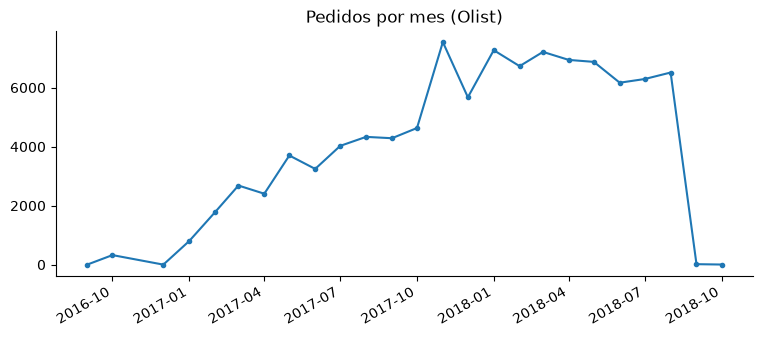

,compradores,pct_recompra
0,93358,3.0


In [2]:
mes = q("""SELECT date_trunc('month', order_purchase_timestamp) AS mes, count(*) AS pedidos
FROM orders GROUP BY 1 ORDER BY 1""")
ax = mes.plot(x="mes", y="pedidos", legend=False, marker="o", ms=3, title="Pedidos por mes (Olist)")
ax.set_xlabel(""); plt.show()

q("""WITH c AS (
  SELECT c.customer_unique_id, count(DISTINCT o.order_id) AS pedidos
  FROM orders o JOIN customers c USING (customer_id)
  WHERE o.order_status = 'delivered' GROUP BY 1)
SELECT count(*) AS compradores, round(100 * avg((pedidos > 1)::INT), 2) AS pct_recompra FROM c""")

## Olist: embudo de captación de vendedores

Lead (MQL) → contrato cerrado → vendedor con ventas. Es la palanca de **captación**.

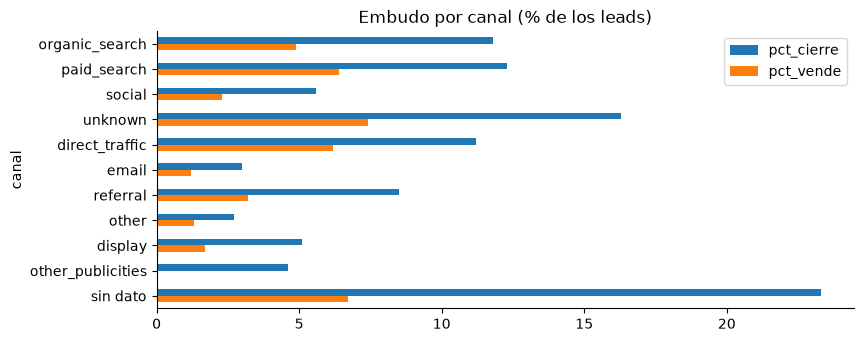

,canal,leads,cerrados,con_ventas,pct_cierre,pct_vende
0,organic_search,2296,271,113,11.8,4.9
1,paid_search,1586,195,101,12.3,6.4
2,social,1350,75,31,5.6,2.3
3,unknown,1099,179,81,16.3,7.4
4,direct_traffic,499,56,31,11.2,6.2
5,email,493,15,6,3.0,1.2
6,referral,284,24,9,8.5,3.2
7,other,150,4,2,2.7,1.3
8,display,118,6,2,5.1,1.7
9,other_publicities,65,3,0,4.6,0.0


In [3]:
canal = q("""SELECT coalesce(m.origin, 'sin dato') AS canal, count(*) AS leads,
  count(d.mql_id) AS cerrados,
  count(DISTINCT CASE WHEN i.seller_id IS NOT NULL THEN d.seller_id END) AS con_ventas
FROM marketing_qualified_leads m
LEFT JOIN closed_deals d USING (mql_id)
LEFT JOIN (SELECT DISTINCT seller_id FROM order_items) i ON i.seller_id = d.seller_id
GROUP BY 1 ORDER BY leads DESC""")
canal["pct_cierre"] = (100 * canal.cerrados / canal.leads).round(1)
canal["pct_vende"] = (100 * canal.con_ventas / canal.leads).round(1)
ax = canal.set_index("canal")[["pct_cierre", "pct_vende"]].plot.barh(title="Embudo por canal (% de los leads)")
ax.invert_yaxis(); plt.show()
canal

## Complete Journey: retención y campañas

Hogares que vuelven y campañas dirigidas (no aleatorias). Es la palanca de **retención**.

In [4]:
display(q("""WITH h AS (SELECT household_id, count(DISTINCT basket_id) AS canastas, sum(sales_value) AS ventas
  FROM cj_transactions GROUP BY 1)
SELECT count(*) AS hogares, median(canastas) AS mediana_canastas, round(100 * avg((canastas > 1)::INT), 1) AS pct_recompra,
  round(median(ventas)) AS mediana_ventas_anual FROM h"""))
q("""SELECT d.campaign_type AS tipo, count(DISTINCT d.campaign_id) AS campañas, count(DISTINCT c.household_id) AS hogares,
  min(d.start_date) AS desde, max(d.end_date) AS hasta
FROM cj_campaign_descriptions d JOIN cj_campaigns c USING (campaign_id) GROUP BY 1 ORDER BY 1""")

,hogares,mediana_canastas,pct_recompra,mediana_ventas_anual
0,2469,43.0,98.7,1210.0


,tipo,campañas,hogares,desde,hasta
0,Type A,4,1490,2017-02-08,2017-12-24
1,Type B,17,995,2016-12-06,2018-02-04
2,Type C,6,397,2016-11-14,2018-02-28


## Experimentos: Hillstrom y Lenta

Asignación aleatoria: la diferencia entre brazos **es** el efecto incremental.

In [5]:
display(q("""SELECT segment AS brazo, count(*) AS n, round(100 * avg(visit), 2) AS pct_visita,
  round(100 * avg(conversion), 2) AS pct_conversion, round(avg(spend), 3) AS gasto_medio
FROM hillstrom GROUP BY 1 ORDER BY 1"""))
q('SELECT "group" AS brazo, count(*) AS n, round(100 * avg(response_att), 2) AS pct_respuesta FROM lenta GROUP BY 1')

,brazo,n,pct_visita,pct_conversion,gasto_medio
0,Mens E-Mail,21307,18.28,1.25,1.423
1,No E-Mail,21306,10.62,0.57,0.653
2,Womens E-Mail,21387,15.14,0.88,1.077


,brazo,n,pct_respuesta
0,control,171137,10.26
1,test,515892,11.01


## Atribución: recorridos con la verdad conocida

In [6]:
import json
from growth_lab.ingest import CRUDO
verdad = json.loads((CRUDO / "atribucion" / "ground_truth.json").read_text())
costos = pd.DataFrame(verdad["dgp"]["channels"]).T[["weight", "cost"]]
costos["contribucion_real"] = pd.Series(verdad["aggregate_true_contribution"])
display(q("SELECT count(*) AS recorridos, round(100 * avg(converted), 2) AS pct_conversion, round(avg(n_touch), 2) AS toques FROM attr_journeys"))
costos.sort_values("contribucion_real", ascending=False)

,recorridos,pct_conversion,toques
0,500000,5.99,2.7


,weight,cost,contribucion_real
paid_search,1.10,1.20,0.263846
social,0.70,0.80,0.185640
organic_search,0.80,0.00,0.142526
email,0.90,0.05,0.131299
display,0.35,0.40,0.112032
direct,1.00,0.00,0.110702
referral,0.50,0.10,0.053955


## Mis conclusiones (Neider)

_Escribe aquí, en tus palabras, qué te dice cada fuente y qué limita. Guía:_

1. Captación (Olist): …
2. Retención (Complete Journey): …
3. Experimentos (Hillstrom y Lenta): …
4. Atribución: …
5. Qué no se puede responder con estos datos: …